In [1]:
import sys, json, collections, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
import engine_api as ea, pandas as pd
import design_helpers as dz
from design_helpers import PAL, display, HTML, plt, np
dz.setup()
dz.hero("The deterministic engine", "How it works, what it decides, and how to call it from any notebook", "41 rules · 37 checks in plain code · the verdict is computed, never judged")

**What this notebook is for:** to show the complete engine (rules, thresholds, verdict) and leave it **as a function that other notebooks can call**. The final notebook uses `engine_api` to check, with the real engine, that every fraud we fabricated *does pass* receipt by receipt.

**The original task:** given a batch of receipts and 9 policy documents (41 rules with an ID), decide for each receipt `pass`, `review` or `flag`, citing the rule.

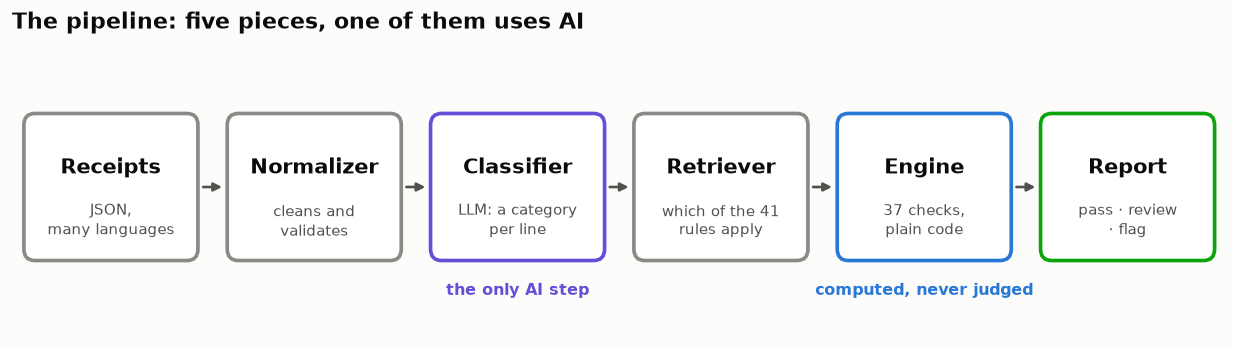

In [2]:
dz.pipeline_diagram()

**Design principle (EXC-01): the disposition is computed, not judged.** Any medium, high or critical exception → `flag`; only low exceptions or only signals → `review`; nothing → `pass`.

In [3]:
DATOS = pathlib.Path.home()/"finetune_project"/"engine"/"datos"
facts = json.load(open(DATOS/"facts.json"))
print(f"rules with an ID: {facts['n_rule_ids']} · engine's own checks: {len(ea.EXPECTED)} · families: {len(ea.FAMILIES)}")
print("without their own check:", facts['engine']['no_own_check'], "(covered by another rule or by the disposition)")

rules with an ID: 41 · engine's own checks: 37 · families: 11
without their own check: ['EXC-01', 'EXC-02', 'EXC-04', 'MCC-03'] (covered by another rule or by the disposition)


In [4]:
dz.banner(1, 'The 41 rules, by policy document', 'Every rule extracted from the nine policy documents')

Each row is a real rule extracted from the documents. "Own check" = the engine has a function that evaluates it.

In [5]:
rows = []
for rid in facts['rule_ids']:
    r = facts['rules'][rid]
    rows.append({"document": r['file'].replace('.md',''), "rule": rid, "title": r['title'], "own check": "yes" if rid in ea.EXPECTED else "no"})
df = pd.DataFrame(rows)
display(df.style.hide(axis="index").set_properties(**{"text-align": "left"}).map(dz.yes_no_style, subset=["own check"]))

document,rule,title,own check
meals-and-entertainment-policy,ALC-01,Alcohol requires a documented entertainment context,yes
meals-and-entertainment-policy,ALC-02,Alcohol per-attendee cap,yes
meals-and-entertainment-policy,ALC-03,Retail alcohol,yes
receipt-documentation-requirements,DOC-01,Itemization threshold,yes
receipt-documentation-requirements,DOC-02,Legibility,yes
receipt-documentation-requirements,DOC-03,Expense type must match the contents,yes
receipt-documentation-requirements,DOC-04,Foreign currency,yes
meals-and-entertainment-policy,ENT-01,Entertainment venues,yes
meals-and-entertainment-policy,ENT-02,Gambling,yes
approval-and-exception-handling,EXC-01,Receipt disposition,no


In [6]:
dz.banner(2, 'The disposition: the function that decides pass / review / flag', 'The single function behind every verdict')

It is the only verdict logic. It is tested here with the engine's real function.

In [7]:
from validator.disposition import disposition
cases = [("no exception and no signal", [], 0), ("only a signal", [], 1), ("one LOW exception", ["low"], 0), ("one MEDIUM exception", ["medium"], 0), ("HIGH + LOW", ["high","low"], 0), ("CRITICAL", ["critical"], 0)]
display(pd.DataFrame([{"situation": s, "disposition": disposition(sev, n)} for s, sev, n in cases]).style.hide(axis="index").map(dz.status_style, subset=["disposition"]))

situation,disposition
no exception and no signal,pass
only a signal,review
one LOW exception,review
one MEDIUM exception,flag
HIGH + LOW,flag
CRITICAL,flag


In [8]:
dz.banner(3, 'The data: 32 real receipts from the task', 'The 32 receipts the task gives us')

Input exactly as the task delivers it (no answers). Each receipt carries merchant, MCC, date, currency, declared expense type (`submitted_expense_type`), trip (`trip_id`), pre-approval reference and **lines** with descriptions in different languages.

In [9]:
R = [json.loads(l) for l in open(DATOS/"receipts_input.jsonl")]
print(len(R), "receipts ·", sum(len(r['line_items']) for r in R), "lines")
print("declared types:", dict(collections.Counter(r['submitted_expense_type'] for r in R)))
print("entities:", dict(collections.Counter(r['entity'] for r in R)), "· line languages:", facts['dataset']['languages'])
r = R[1]; print("\nExample, one full receipt:"); print(json.dumps({k: v for k, v in r.items() if k != 'line_items'}, ensure_ascii=False, indent=1)); print("lines:"); _ = [print("  ", l['line_id'], l['description_raw'], f"${l['amount_usd']}") for l in r['line_items']]

32 receipts · 79 lines
declared types: {'Meals - Individual': 8, 'Client Entertainment': 5, 'Office Supplies': 3, 'Meals - Team': 4, 'Lodging': 2, 'Computer Equipment': 3, 'Travel - Other': 4, 'Client Gifts': 2, 'Software': 1}
entities: {'GLOBAL': 27, 'EMEA': 3, 'APAC': 2} · line languages: {'de': 3, 'en': 68, 'es': 2, 'fr': 3, 'ja': 2, 'pt': 1}

Example, one full receipt:
{
 "receipt_id": "RCP-002",
 "employee_id": "E-1042",
 "employee_country": "US",
 "entity": "GLOBAL",
 "submitted_expense_type": "Client Entertainment",
 "merchant_name": "Verona Grill",
 "mcc": "5812",
 "mcc_description": "Eating places and restaurants",
 "transaction_datetime": "2026-04-16T19:45:00",
 "currency": "USD",
 "fx_rate_to_usd": 1.0,
 "total_amount": 234.0,
 "total_amount_usd": 234.0,
 "attendee_count": 4,
 "trip_id": "TRIP-0091",
 "trip_nights": 3,
 "pre_approval_ref": "PA-2026-0412",
 "itemized": true
}
lines:
   RCP-002-L1 Prix fixe dinner $136.0
   RCP-002-L2 Chianti Classico bottle $68.0
   RCP-002-L

In [10]:
dz.banner(4, "The engine on the 32 receipts: the pipeline's result is reproduced", "Can we reproduce the pipeline's decisions?")

The classifier (LLM) already assigned categories to each line; those categories are in the saved report. Here we **re-run only the engine** (code, no network) with those categories and compare the disposition with the report's.
One line needs outside help: `RCP-022-L2` is a gift to a public official, a fact the classifier delivers as a *recipient* (`gift_for`); we set it by hand because the report does not store it.

In [11]:
rep = {r['receipt_id']: r for r in map(json.loads, open(DATOS/"report.jsonl"))}
cats, uncertain = {}, {}
for rid, r in rep.items():
    for l in r['line_items']:
        cats[l['line_id']] = l['category']
        if l['confidence_band'] == 'low': uncertain.setdefault(rid, set()).add(l['line_id'])
res = ea.evaluate_receipts(R, cats, {"RCP-022-L2": ("government_official", "R. Delgado")}, uncertain)
same = sum(res[k].disposition == rep[k]['disposition'] for k in rep)
print(f"recomputed disposition = report disposition in {same}/{len(rep)} receipts")
print("distribution:", ea.summary(res))

recomputed disposition = report disposition in 32/32 receipts
distribution: {'pass': 9, 'flag': 18, 'review': 5}


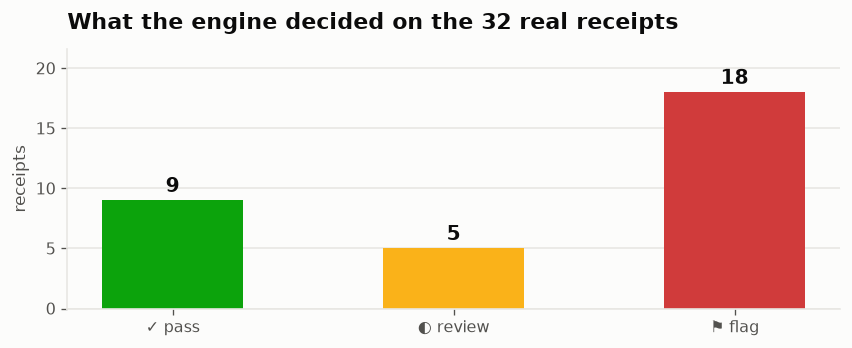

In [12]:
cnt = ea.summary(res); col = {"pass": PAL["good"], "review": PAL["warn"], "flag": PAL["crit"]}; icon = {"pass": "✓ pass", "review": "◐ review", "flag": "⚑ flag"}
dz.kpis([(sum(cnt.values()), "receipts", "real receipts from the task", PAL["muted"]), (cnt.get("pass", 0), "pass", "nothing fired", PAL["good"]), (cnt.get("review", 0), "review", "low exception or only signals", PAL["warn"]), (cnt.get("flag", 0), "flag", "medium, high or critical exception", PAL["crit"])])
fig, ax = plt.subplots(figsize=(7.2, 3)); order = ["pass", "review", "flag"]
bars = ax.bar([icon[k] for k in order], [cnt.get(k, 0) for k in order], color=[col[k] for k in order], width=.5)
dz.label_bars(ax, bars, "{:.0f}", dy=.3, fs=12); ax.set_ylim(0, max(cnt.values()) * 1.2); ax.set_ylabel("receipts"); ax.set_title("What the engine decided on the 32 real receipts"); ax.grid(False); ax.yaxis.grid(True)
plt.tight_layout(); plt.show()

In [13]:
rows = [{"receipt": k, "type": next(r['submitted_expense_type'] for r in R if r['receipt_id'] == k), "disposition": x.disposition, "rules fired": ", ".join(f"{a}({b})" for a, b, _ in x.fired) or "-"} for k, x in res.items()]
display(pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left"}).map(dz.status_style, subset=["disposition"]))

receipt,type,disposition,rules fired
RCP-001,Meals - Individual,pass,-
RCP-002,Client Entertainment,pass,-
RCP-003,Office Supplies,pass,-
RCP-004,Meals - Team,pass,-
RCP-005,Lodging,pass,-
RCP-006,Computer Equipment,pass,-
RCP-007,Meals - Team,pass,-
RCP-008,Meals - Team,pass,-
RCP-009,Travel - Other,pass,-
RCP-010,Meals - Individual,flag,ALC-01(high)


In [14]:
dz.banner(5, 'Boundary tests: one cent changes the verdict', 'Every threshold is an exact operator')

This shows that each threshold is an **exact operator** (`>` and not `>=`). Each pair is the same receipt with an amount on either side of the limit, run with the real engine.

In [15]:
c = ea.create_receipt
def gift(m): r,k=c("G1","Client Gifts","Southern Flowers","5992","2026-05-06T11:00:00",[("Gift basket","gift",m,1)]); return r,k,{r["line_items"][0]["line_id"]:("client","Ana Perez")}
def tech(m,pa=None): r,k=c("T1","Computer Equipment","Bitforge","5045","2026-05-06T11:00:00",[("USB hub","computer_accessory",m,1)],pre_approval=pa); return r,k,None
def no_detail(m): r,k=c("D1","Office Supplies","Stationery Shop","5943","2026-05-06T11:00:00",[("Assorted stationery","office_supplies",m,1)],itemized=False); return r,k,None
def meal(m): r,k=c("M1","Meals - Individual","Diner","5812","2026-05-06T13:00:00",[("Meal","food_beverage",m,1)],attendees=1,trip="TRIP-1001",nights=2); return r,k,None
def alcohol(): r,k=c("A1","Meals - Individual","Diner","5812","2026-05-06T20:00:00",[("Dinner","food_beverage",30,1),("Beer","alcohol",8,1)],attendees=1,trip="TRIP-1001",nights=2); return r,k,None
def early_morning(): r,k=c("N1","Office Supplies","Stationery Shop","5943","2026-05-06T03:10:00",[("Paper","office_supplies",20,1)]); return r,k,None
cases = [("Client gift $50.00 (limit $50 per recipient)", *gift(50.0)), ("Client gift $50.01", *gift(50.01)),
         ("Accessory $200.00 (limit $200 per item)", *tech(200.0)), ("Accessory $200.01 without pre-approval", *tech(200.01)), ("Accessory $250.00 with pre-approval PA", *tech(250.0, "PA-2026-0001")),
         ("Receipt without itemization $75.00 (limit $75)", *no_detail(75.0)), ("Receipt without itemization $75.01", *no_detail(75.01)),
         ("Individual meal $75.00 (daily cap $75)", *meal(75.0)), ("Individual meal $75.01", *meal(75.01)),
         ("Alcohol line", *alcohol()), ("Purchase at 03:10 am (00:00–05:00)", *early_morning())]
display(pd.DataFrame(ea.probe(cases), columns=["case", "disposition", "rules fired"]).style.hide(axis="index").set_properties(**{"text-align": "left"}).map(dz.status_style, subset=["disposition"]))

case,disposition,rules fired
Client gift $50.00 (limit $50 per recipient),pass,-
Client gift $50.01,flag,GIFT-01(medium)
Accessory $200.00 (limit $200 per item),pass,-
Accessory $200.01 without pre-approval,flag,TECH-02(medium)
Accessory $250.00 with pre-approval PA,pass,-
Receipt without itemization $75.00 (limit $75),pass,-
Receipt without itemization $75.01,flag,DOC-01(medium)
Individual meal $75.00 (daily cap $75),pass,-
Individual meal $75.01,flag,MEAL-01(medium)
Alcohol line,flag,ALC-01(high)


In [16]:
dz.banner(6, 'A receipt from the inside: which rule was considered and why', 'The retriever, the checks and what got superseded')

The **retriever** proposes a subset of rules per receipt; the engine evaluates all of them, and if it fires one the retriever did not propose, that is a retriever error (`ERR-retriever`) that sends the receipt to `review` (fail closed).

In [17]:
x = res["RCP-022"]
print("disposition:", x.disposition); print("rules proposed by the retriever:", ", ".join(x.considered)); print("fired:", x.fired); print("superseded:", x.superseded or "none")

disposition: flag
rules proposed by the retriever: DOC-02, DOC-03, EXC-03, GIFT-01, GIFT-03, GIFT-04, MEAL-01, MEAL-02, REG-05, TIME-01, TIME-03
fired: [('GIFT-04', 'critical', 'provided to a government official: route to Compliance')]
superseded: ['GIFT-01']


In [18]:
dz.banner(7, 'How to call it from other notebooks', 'The function other notebooks call')

```python
import engine_api as ea
res = ea.evaluate_receipts(receipts, categories, gift_for=None, uncertain=None)   # batch of real receipts
res = ea.evaluate_history(h)                                                      # red-team history
rec, cats = ea.create_receipt(id, expense_type, merchant, mcc, when, lines, entity=..., attendees=..., trip=..., nights=..., pre_approval=..., itemized=..., currency=...)
rows = ea.probe(cases)                                                            # (label, disposition, fired)
ea.summary(res)                # {'pass': n, 'review': n, 'flag': n}
res["RCP-001"].disposition     # 'pass' | 'review' | 'flag'
res["RCP-001"].fired           # [(rule, severity, detail)]  (severity: low/medium/high/critical/signal)
```
## What this engine **cannot** see
Almost all the rules look at **one receipt at a time**. There are only limited cross-checks: meals by the same employee on the same day (MEAL-02, REG-03), health items per trip (HEALTH) and splitting around a cap at the same merchant (TIME-03). An employee who **splits, repeats or mixes** expenses across several receipts, each within the limit, **triggers nothing**. That is the opportunity the final notebook explores.